In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [6]:
df = pd.read_csv('../module-1/titanic_data_updated.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
df.drop(['PassengerId', 'Name', 'Ticket'], axis=1, inplace=True)

In [8]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S


In [13]:
df.drop('Cabin', axis=1, inplace=True)

In [14]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,no,third,male,22.0,1,0,7.2500,S
1,yes,first,female,38.0,1,0,71.2833,C
2,yes,third,female,26.0,0,0,7.9250,S
3,yes,first,female,35.0,1,0,53.1000,S
4,no,third,male,35.0,0,0,8.0500,S


In [15]:
# features

x = df.drop(['Survived'], axis=1)
x

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,third,male,22.0,1,0,7.2500,S
1,first,female,38.0,1,0,71.2833,C
2,third,female,26.0,0,0,7.9250,S
3,first,female,35.0,1,0,53.1000,S
4,third,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...
886,second,male,27.0,0,0,13.0000,S
887,first,female,19.0,0,0,30.0000,S
888,third,female,NaN,1,2,23.4500,S
889,first,male,26.0,0,0,30.0000,C


In [17]:
# target column

y = df['Survived']
y.head()

0     no
1    yes
2    yes
3    yes
4     no
Name: Survived, dtype: str

#### Train and Split

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [22]:
x_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
709,third,male,NaN,1,1,15.2458,C
439,second,male,31.0,0,0,10.5000,S
840,third,male,20.0,0,0,7.9250,S
720,second,female,6.0,0,1,33.0000,S
39,third,female,14.0,1,0,11.2417,C
...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,S
773,third,male,NaN,0,0,7.2250,C
25,third,female,38.0,1,5,31.3875,S
84,second,female,17.0,0,0,10.5000,S


#### Imputation with Pandas

In [46]:
# imputation with age mean

age_mean = x_train['Age'].mean()

x_train['age_mean_imputor'] = x_train['Age'].fillna(age_mean)
x_test['age_mean_imputor'] = x_test['Age'].fillna(age_mean)
x_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,age_mean_imputor,age_median_imputor
331,first,male,45.5,0,0,28.5000,S,45.500000,45.5
733,second,male,23.0,0,0,13.0000,S,23.000000,23.0
382,third,male,32.0,0,0,7.9250,S,32.000000,32.0
704,third,male,26.0,1,0,7.8542,S,26.000000,26.0
813,third,female,6.0,4,2,31.2750,S,6.000000,6.0
...,...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,S,21.000000,21.0
270,first,male,NaN,0,0,31.0000,S,29.498846,28.0
860,third,male,41.0,2,0,14.1083,S,41.000000,41.0
435,first,female,14.0,1,2,120.0000,S,14.000000,14.0


In [43]:
# imputation with age median

age_median = x_train['Age'].median()

x_train['age_median_imputor'] = x_train['Age'].fillna(age_median)
x_test['age_median_imputor'] = x_test['Age'].fillna(age_median)

In [44]:
x_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,age_mean_imputor,age_median_imputor
331,first,male,45.5,0,0,28.5000,S,45.500000,45.5
733,second,male,23.0,0,0,13.0000,S,23.000000,23.0
382,third,male,32.0,0,0,7.9250,S,32.000000,32.0
704,third,male,26.0,1,0,7.8542,S,26.000000,26.0
813,third,female,6.0,4,2,31.2750,S,6.000000,6.0
...,...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,S,21.000000,21.0
270,first,male,NaN,0,0,31.0000,S,29.498846,28.0
860,third,male,41.0,2,0,14.1083,S,41.000000,41.0
435,first,female,14.0,1,2,120.0000,S,14.000000,14.0


<Axes: xlabel='age_mean_imputor', ylabel='Density'>

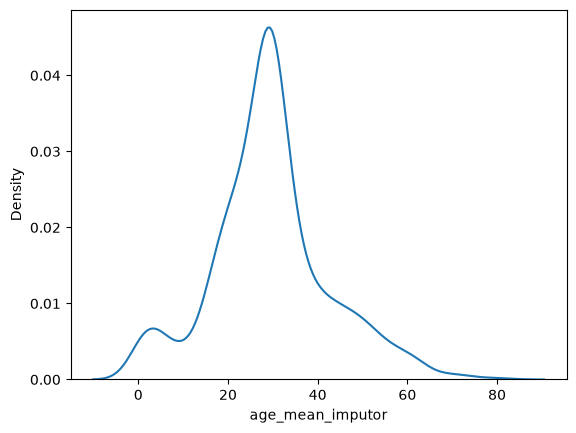

In [55]:
sns.kdeplot(data=x_train, x='age_mean_imputor')

<Axes: xlabel='age_median_imputor', ylabel='Density'>

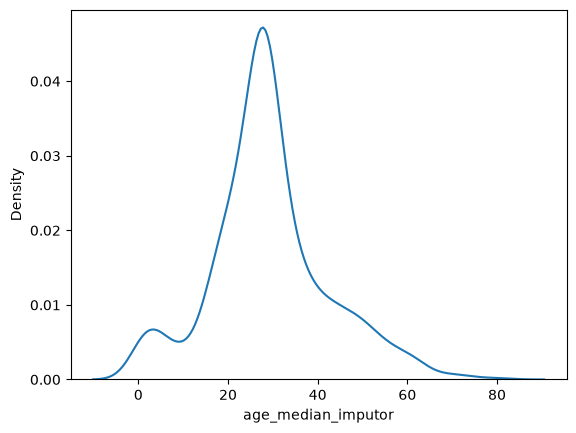

In [56]:
sns.kdeplot(data=x_train, x='age_median_imputor')

#### Imputation with Simple Imputer

In [57]:
from sklearn.impute import SimpleImputer

In [ ]:
# dropping previously imputed columns

x_train.drop(['age_mean_imputor', 'age_median_imputor'], axis=1, inplace=True)

In [ ]:
# imputation for x train

age_imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

age_imputer.fit(x_train[['Age']])

x_train['Age'] = age_imputer.transform(x_train[['Age']]).ravel() # converting to 1d

In [61]:
x_train.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64

In [63]:
# imputation for x test

print(x_test['Age'].isnull().sum())

x_test['Age'] = age_imputer.transform(x_test[['Age']]).ravel() # convert to 1d

print(x_test['Age'].isnull().sum())

37
0


In [64]:
embarked_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

embarked_imputer.fit(x_train[['Embarked']])

x_train['Embarked'] = embarked_imputer.transform(x_train[['Embarked']]).ravel()
x_test['Embarked'] = embarked_imputer.transform(x_test[['Embarked']]).ravel()

In [70]:
print(x_test['Embarked'].hasnans)

False


In [73]:
# cabin imputation

df = pd.read_csv('../module-1/titanic_data_updated.csv')

x_train['Cabin'] = df['Cabin']
x_test['Cabin'] = df['Cabin']

In [77]:
cabin_imputer = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='Missing', add_indicator=True)

cabin_imputer.fit(x_train[['Cabin']])

x_train[['Cabin', 'Cabin_missing_indicator']] = cabin_imputer.transform(x_train[['Cabin']])
x_test[['Cabin', 'Cabin_missing_indicator']] = cabin_imputer.transform(x_test[['Cabin']])

In [86]:
x_train.isnull().sum()
x_test.isnull().sum()

Pclass                     0
Sex                        0
Age                        0
SibSp                      0
Parch                      0
Fare                       0
Embarked                   0
Cabin                      0
Cabin_missing_indicator    0
dtype: int64